%% [markdown]
# Capítulo 10: Event-Driven — Insider Trading Legal (Form 4)

Estrategia de seguimiento de compras de insiders mediante formularios SEC Form 4

**Estrategia:** Detectar compras netas > $100k por parte de ejecutivos C-level (CEO, CFO, COO) en los últimos 60 días, con peso dinámico según el monto de la compra. Mantener posición durante 75 días o hasta el stop-loss del -8%, con un máximo de 8 posiciones simultáneas.

**Advertencia:** (1) Los datos de SEC EDGAR pueden tener retrasos de 1-2 días hábiles. (2) El universo de empresas con insider buying activo es limitado en cada momento. (3) Algunas compras forman parte de programas automáticos (10b5-1 plans) que no reflejan la visión actual del mercado.

**Objetivo:** Medir si las compras significativas de insiders generan alpha frente al Buy & Hold y documentar las limitaciones de trabajar con datos gratuitos de la SEC en tiempo real.

## BLOQUE 0: CONFIGURACIÓN DE LA ESTRATEGIA — INSIDER TRADING (FORM 4)

In [1]:
# ==============================================================================
# BLOQUE 0: CONFIGURACIÓN — INSIDER TRADING LEGAL (FORM 4)
# ==============================================================================

# --- Parámetros financieros ---
CAPITAL_INICIAL = 10000.0
COSTE_TRANSACCION = 0.001  # 0.1% por operación
BENCHMARK = 'SPY'
RF_LIBRE = 0.02

# --- Parámetros de Insider Trading ---
UMBRAL_COMPRA_USD = 100000  # Compras > $100k
VENTANA_DRIFT_DIAS = 75  # Mantener posición 75 días
STOP_LOSS_PCT = 0.08  # Stop-loss del 8%
MAX_POSICIONES = 8  # Máximo 8 posiciones simultáneas
FREQ_REBALANCEO = 'W'  # Rebalanceo semanal

# --- Universo de empresas (ejemplo: grandes caps con insider trading activo) ---
UNIVERSO_INSIDER = {
    'tecnologia': {
        'Apple': {'isin': 'US0378331005', 'ticker': 'AAPL'},
        'Microsoft': {'isin': 'US5949181045', 'ticker': 'MSFT'},
        'Nvidia': {'isin': 'US67066G1040', 'ticker': 'NVDA'},
        'Amazon': {'isin': 'US0231351067', 'ticker': 'AMZN'},
    },
    'financiero': {
        'JPMorgan': {'isin': 'US46625H1005', 'ticker': 'JPM'},
        'Bank_of_America': {'isin': 'US0605051046', 'ticker': 'BAC'},
        'Goldman_Sachs': {'isin': 'US38141G1040', 'ticker': 'GS'},
    },
    'salud': {
        'Johnson_&_Johnson': {'isin': 'US4781601046', 'ticker': 'JNJ'},
        'Pfizer': {'isin': 'US7170811035', 'ticker': 'PFE'},
        'UnitedHealth': {'isin': 'US91324P1021', 'ticker': 'UNH'},
    },
    'consumo': {
        'Procter_&_Gamble': {'isin': 'US7427181091', 'ticker': 'PG'},
        'Coca-Cola': {'isin': 'US1912161007', 'ticker': 'KO'},
        'Walmart': {'isin': 'US9311421039', 'ticker': 'WMT'},
    },
    'benchmark': {
        'SPDR_S&P_500': {'isin': 'US78462F1030', 'ticker': 'SPY'},
    }
}

NOMBRE_ESTRATEGIA = "Insider Trading Legal (Form 4)"
FECHA_INICIO = ""
FECHA_FIN = ""

print("="*70)
print("✅ Configuración Insider Trading Legal cargada:")
print("="*70)
print(f"   • Estrategia: {NOMBRE_ESTRATEGIA}")
print(f"   • Capital inicial: €{CAPITAL_INICIAL:,.2f}")
print(f"   • Umbral de compra: > ${UMBRAL_COMPRA_USD:,.0f}")
print(f"   • Ventana de tenencia: {VENTANA_DRIFT_DIAS} días")
print(f"   • Stop-loss: {STOP_LOSS_PCT:.0%}")
print(f"   • Máx. posiciones: {MAX_POSICIONES}")
print(f"   • Comisión: {COSTE_TRANSACCION*100:.2f}%")
print("="*70)

✅ Configuración Insider Trading Legal cargada:
   • Estrategia: Insider Trading Legal (Form 4)
   • Capital inicial: €10,000.00
   • Umbral de compra: > $100,000
   • Ventana de tenencia: 75 días
   • Stop-loss: 8%
   • Máx. posiciones: 8
   • Comisión: 0.10%


## BLOQUE 1: ENTORNO E IMPORTACIONES

In [2]:
# ==============================================================================
# BLOQUE 1: ENTORNO, IMPORTACIONES Y MOTOR MODULAR
# ==============================================================================

print("="*70)
print("⚠️ AVISO LEGAL: Fines exclusivamente educativos e investigativos.")
print("="*70)

import sys, os, warnings, inspect
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import yfinance as yf

# Búsqueda de la carpeta 'core'
def buscar_core():
    try:
        ruta_actual = Path(__file__).parent.resolve()
    except NameError:
        ruta_actual = Path.cwd().resolve()
    
    for nivel in [ruta_actual] + list(ruta_actual.parents)[:6]:
        carpeta_core = nivel / 'core'
        if (carpeta_core.is_dir() and (carpeta_core / 'gestor_proyecto.py').exists()):
            return nivel, carpeta_core
    return None, None

project_root, ruta_core = buscar_core()

if project_root is None:
    raise FileNotFoundError("❌ No se pudo encontrar la carpeta 'core'.")

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

try:
    from core.gestor_proyecto import GestorProyecto
    from core.gestor_datos import GestorDatos
    from core.backtest import MotorBacktestDinamico, CalculadorMetricas
    from core.informes import GeneradorInformes
    print("✅ Módulos importados correctamente.")
except ImportError as e:
    print(f"❌ Error importando módulos: {e}")
    raise SystemExit

BASE_DIR = os.path.dirname(ruta_core) if ruta_core else os.getcwd()

# Función auxiliar para adaptar argumentos
def construir_kwargs(cls, candidatos_kwargs):
    try:
        target = cls.__init__ if inspect.isclass(cls) else cls
        firma = inspect.signature(target)
        params = firma.parameters
    except (ValueError, TypeError):
        return {}
    kwargs_filtrados = {}
    for nombre_param in params:
        if nombre_param == 'self': continue
        for clave, valor in candidatos_kwargs.items():
            if clave.lower().replace(' ', '') == nombre_param.lower().replace(' ', ''):
                kwargs_filtrados[nombre_param] = valor
                break
    return kwargs_filtrados

⚠️ AVISO LEGAL: Fines exclusivamente educativos e investigativos.
✅ Módulos importados correctamente.


## BLOQUE 2: LIMPIEZA DE DIRECTORIOS Y FECHAS

In [3]:
# ==============================================================================
# BLOQUE 2: GESTIÓN DEL ENTORNO DE TRABAJO
# ==============================================================================

print("\n" + "="*70)
print("🧹 BLOQUE 2: GESTIÓN DEL ENTORNO DE TRABAJO")
print("="*70)

try:
    gestor_proy = GestorProyecto(dir_base=project_root)
except TypeError:
    gestor_proy = GestorProyecto()
    gestor_proy.BASE_DIR = project_root

RUTA_CAP10 = Path(gestor_proy.DIRS.get("OUTPUTS", project_root / "outputs")) / "cap10_insider_trading"
RUTA_FIGURES_CAP10 = RUTA_CAP10 / "figures"
RUTA_FIGURES_CAP10.mkdir(parents=True, exist_ok=True)

print(f"✅ Entorno configurado. Base: {gestor_proy.BASE_DIR}")
print(f"📂 Directorio de figuras: {RUTA_FIGURES_CAP10}")


🧹 BLOQUE 2: GESTIÓN DEL ENTORNO DE TRABAJO
✅ Entorno configurado. Base: /media/enri/MI_PROYECTO/Estrategias_no_Convencionales
📂 Directorio de figuras: /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/outputs/cap10_insider_trading/figures


## BLOQUE 3: MENÚ DEL GESTOR DE DATOS

In [4]:
# ==============================================================================
# BLOQUE 3: MENÚ DE ESTRÉS (SELECCIÓN DE PERÍODO)
# ==============================================================================

print("\n" + "="*70)
print("📉 BLOQUE 3: MENÚ DE ESTRÉS")
print("="*70)
print("  1. Histórico Completo (2020-Hoy)")
print("  2. Crisis Financiera (2007-2009)")
print("  3. Periodo Personalizado")

opcion = input("\nIntroduce tu opción (1-3) [1]: ").strip() or "1"

if opcion == '1':
    FECHA_INICIO, FECHA_FIN, evento = "2020-01-01", None, "Histórico Completo"
elif opcion == '2':
    FECHA_INICIO, FECHA_FIN, evento = "2007-10-01", "2009-03-31", "Crisis Financiera"
else:
    evento = "Periodo Personalizado"
    FECHA_INICIO = input("   > Fecha de inicio (YYYY-MM-DD): ").strip()
    FECHA_FIN = input("   > Fecha de fin (YYYY-MM-DD): ").strip() or None

if FECHA_FIN is None:
    from datetime import datetime
    FECHA_FIN = datetime.now().strftime("%Y-%m-%d")

print(f"\n⏳ Configurado: {evento} ({FECHA_INICIO} a {FECHA_FIN})")


📉 BLOQUE 3: MENÚ DE ESTRÉS
  1. Histórico Completo (2020-Hoy)
  2. Crisis Financiera (2007-2009)
  3. Periodo Personalizado



Introduce tu opción (1-3) [1]:  3
   > Fecha de inicio (YYYY-MM-DD):  2016-01-04
   > Fecha de fin (YYYY-MM-DD):  2026-10-15



⏳ Configurado: Periodo Personalizado (2016-01-04 a 2026-10-15)


## BLOQUE 4: GENERACIÓN DE SEÑALES (CON FALLBACK PEDAGÓGICO)

In [6]:
# ==============================================================================
# BLOQUE 4: GESTOR DE DATOS (Insider Trading - Autocontenido)
# ==============================================================================

print(f"\n✅ Período configurado: {evento}")
print(f"   Inicio: {FECHA_INICIO} | Fin: {FECHA_FIN}\n")

# ==============================================================================
# VARIABLES POR DEFECTO (si el Bloque 0 no se ejecutó)
# ==============================================================================
if 'UNIVERSO_INSIDER' not in globals():
    print("⚠️  UNIVERSO_INSIDER no definido. Usando valores por defecto...")
    UNIVERSO_INSIDER = {
        'tecnologia': {
            'Apple': {'isin': 'US0378331005', 'ticker': 'AAPL'},
            'Microsoft': {'isin': 'US5949181045', 'ticker': 'MSFT'},
        },
        'benchmark': {
            'SPDR_S&P_500': {'isin': 'US78462F1030', 'ticker': 'SPY'},
        }
    }

# ==============================================================================
# FUNCIÓN AUXILIAR: construir_kwargs (si no existe)
# ==============================================================================
if 'construir_kwargs' not in globals():
    import inspect
    def construir_kwargs(cls, candidatos_kwargs):
        try:
            target = cls.__init__ if inspect.isclass(cls) else cls
            firma = inspect.signature(target)
            params = firma.parameters
        except (ValueError, TypeError):
            return {}
        kwargs_filtrados = {}
        for nombre_param in params:
            if nombre_param == 'self':
                continue
            for clave, valor in candidatos_kwargs.items():
                if clave.lower().replace(' ', '') == nombre_param.lower().replace(' ', ''):
                    kwargs_filtrados[nombre_param] = valor
                    break
        return kwargs_filtrados

# ==============================================================================
# INICIALIZAR GESTOR DE DATOS
# ==============================================================================
print("🔄 Inicializando Gestor de Datos...")
try:
    kwargs_gestor = {
        "diccionario_datos": UNIVERSO_INSIDER,
        "fecha_inicio": FECHA_INICIO,
        "fecha_fin": FECHA_FIN,
        "gestor_proyecto": gestor_proy
    }
    kwargs_filtrados = construir_kwargs(GestorDatos, kwargs_gestor)
    gestor = GestorDatos(**kwargs_filtrados)
    print("✅ Gestor de Datos inicializado correctamente.\n")
except Exception as e:
    print(f"❌ ERROR al inicializar GestorDatos: {e}")
    raise SystemExit

# ==============================================================================
# DESCARGA AUTOMÁTICA (sin menú interactivo)
# ==============================================================================
print("📥 Descargando/Actualizando cotizaciones desde Yahoo Finance...")
try:
    gestor.gestionar_descarga_cotizaciones()
    print("✅ Descarga completada.\n")
except Exception as e:
    print(f"⚠️  Error en la descarga: {e}")

# ==============================================================================
# GENERAR CARTERA AUTOMÁTICAMENTE (CRÍTICO: sin esto, precios_ajustados = None)
# ==============================================================================
print("🔄 Generando cartera automáticamente desde el diccionario...")
try:
    # Intentar diferentes métodos según la versión del GestorDatos
    if hasattr(gestor, '_cartera_por_defecto'):
        gestor._cartera_por_defecto()
        print("✅ Cartera generada con _cartera_por_defecto().\n")
    elif hasattr(gestor, 'generar_cartera_automatica'):
        gestor.generar_cartera_automatica()
        print("✅ Cartera generada con generar_cartera_automatica().\n")
    elif hasattr(gestor, 'preparar_datos_motor'):
        # Algunas versiones preparan directamente sin generar cartera explícita
        print("️  No se encontró método específico. Intentando preparar datos directamente...\n")
    else:
        print("⚠️  No se encontró método para generar cartera automáticamente.")
        print("   Intentando preparar datos directamente...\n")
except Exception as e:
    print(f"⚠️  Error al generar cartera: {e}")

# ==============================================================================
# PREPARAR DATOS DEL MOTOR
# ==============================================================================
print("🔄 Preparando datos para el backtest...")
try:
    gestor.preparar_datos_motor()
    
    precios = gestor.precios_ajustados
    rentabilidades = gestor.rentabilidades_diarias
    
    if precios is None or precios.empty:
        raise ValueError("No se pudieron cargar los datos de precios.")
    
    # Aplanar MultiIndex si existe
    if isinstance(precios.columns, pd.MultiIndex):
        print("⚠️  Detectado MultiIndex. Aplanando columnas...")
        if 'Close' in precios.columns.get_level_values(1):
            precios = precios['Close']
        elif 'Adj Close' in precios.columns.get_level_values(1):
            precios = precios['Adj Close']
        else:
            precios = precios.iloc[:, ::6]
            precios.columns = precios.columns.get_level_values(0)
        precios.columns.name = None
        rentabilidades = precios.pct_change().dropna()
        print("✅ Datos aplanados.\n")
    
    print(f"✅ Datos cargados: {len(precios)} filas, {len(precios.columns)} activos")
    print(f"   • Período: {precios.index[0].strftime('%Y-%m-%d')} a {precios.index[-1].strftime('%Y-%m-%d')}")
    print(f"   • Activos: {list(precios.columns)}\n")
    
except Exception as e:
    print(f"\n❌ ERROR en la preparación de datos: {e}")
    print("\n💡 SOLUCIÓN ALTERNATIVA: Usa el menú interactivo")
    print("   1. Ejecuta: gestor.menu()")
    print("   2. Selecciona '1' para descargar")
    print("   3. Selecciona '6' para ejecutar estrategia")
    raise SystemExit


✅ Período configurado: Periodo Personalizado
   Inicio: 2016-01-04 | Fin: 2026-10-15

🔄 Inicializando Gestor de Datos...
✅ Gestor de Datos inicializado correctamente.

📥 Descargando/Actualizando cotizaciones desde Yahoo Finance...

🗑️ Limpiando CSVs antiguos y descargando desde Yahoo Finance...

📊 Procesando 14 activos...

   📊 Apple
      ✅ Descargado con ticker: AAPL

   📊 Microsoft
      ✅ Descargado con ticker: MSFT

   📊 Nvidia
      ✅ Descargado con ticker: NVDA

   📊 Amazon
      ✅ Descargado con ticker: AMZN

   📊 JPMorgan
      ✅ Descargado con ticker: JPM

   📊 Bank_of_America
      ✅ Descargado con ticker: BAC

   📊 Goldman_Sachs
      ✅ Descargado con ticker: GS

   📊 Johnson_&_Johnson
      ✅ Descargado con ticker: JNJ

   📊 Pfizer
      ✅ Descargado con ticker: PFE

   📊 UnitedHealth
      ✅ Descargado con ticker: UNH

   📊 Procter_&_Gamble
      ✅ Descargado con ticker: PG

   📊 Coca-Cola
      ✅ Descargado con ticker: KO

   📊 Walmart
      ✅ Descargado con ticker: WMT

,Activo,ISIN,Filas,Desde,Hasta,Fuente
0,Apple,US0378331005,2711,2016-01-04,2026-10-14,CSV
1,Microsoft,US5949181045,2711,2016-01-04,2026-10-14,CSV
2,Nvidia,US67066G1040,2711,2016-01-04,2026-10-14,CSV
3,Amazon,US0231351067,2711,2016-01-04,2026-10-14,CSV
4,JPMorgan,US46625H1005,2711,2016-01-04,2026-10-14,CSV
5,Bank_of_America,US0605051046,2711,2016-01-04,2026-10-14,CSV
6,Goldman_Sachs,US38141G1040,2711,2016-01-04,2026-10-14,CSV
7,Johnson_&_Johnson,US4781601046,2711,2016-01-04,2026-10-14,CSV
8,Pfizer,US7170811035,2711,2016-01-04,2026-10-14,CSV
9,UnitedHealth,US91324P1021,2711,2016-01-04,2026-10-14,CSV


✅ 14 activos alineados para el Motor Backtest.

✅ Datos cargados: 2711 filas, 14 activos
   • Período: 2016-01-04 a 2026-10-14
   • Activos: ['Apple', 'Microsoft', 'Nvidia', 'Amazon', 'JPMorgan', 'Bank_of_America', 'Goldman_Sachs', 'Johnson_&_Johnson', 'Pfizer', 'UnitedHealth', 'Procter_&_Gamble', 'Coca-Cola', 'Walmart', 'SPDR_S&P_500']



## BLOQUE 5: GENERADOR DE PESOS DINÁMICO

In [8]:
# ==============================================================================
# BLOQUE 5: GENERADOR DE PESOS (Autocontenido - Insider Trading)
# ==============================================================================

print("\n" + "="*70)
print("⚙️  CONFIGURANDO ESTRATEGIA INSIDER TRADING")
print("="*70)

# ==============================================================================
# VARIABLES POR DEFECTO (si los bloques anteriores no se ejecutaron)
# ==============================================================================
if 'UMBRAL_COMPRA_USD' not in globals():
    print("⚠️  Parámetros de Insider Trading no definidos. Usando valores por defecto...")
    UMBRAL_COMPRA_USD = 100000
    VENTANA_DRIFT_DIAS = 75
    STOP_LOSS_PCT = 0.08
    MAX_POSICIONES = 8

if 'UNIVERSO_INSIDER' not in globals():
    UNIVERSO_INSIDER = {
        'tecnologia': {
            'Apple': {'isin': 'US0378331005', 'ticker': 'AAPL'},
            'Microsoft': {'isin': 'US5949181045', 'ticker': 'MSFT'},
        },
        'benchmark': {
            'SPDR_S&P_500': {'isin': 'US78462F1030', 'ticker': 'SPY'},
        }
    }

# ==============================================================================
# VERIFICAR DATOS DE PRECIOS
# ==============================================================================
if 'precios' not in globals() or precios is None or precios.empty:
    raise ValueError("❌ No hay precios ajustados. Ejecuta Bloque 4 primero.")

# Normalizar índice de precios
precios_sig = precios.copy()
idx_norm = pd.DatetimeIndex(precios_sig.index)
if idx_norm.tz is not None:
    idx_norm = idx_norm.tz_localize(None)
precios_sig.index = idx_norm.normalize()

print(f"📊 Datos disponibles: {len(precios_sig)} filas")
print(f"   • Período: {precios_sig.index[0].date()} → {precios_sig.index[-1].date()}")

# ==============================================================================
# GENERAR SEÑALES DE INSIDER (si no existen)
# ==============================================================================
if 'df_señales_raw' not in globals():
    print("\n⚠️  df_señales_raw no definido. Generando señales internamente...")
    
    import yfinance as yf
    
    # Mapeo de tickers a columnas
    ticker_a_columna = {}
    for categoria, activos in UNIVERSO_INSIDER.items():
        for nombre, info in activos.items():
            ticker = info['ticker']
            ticker_a_columna[ticker] = nombre
    
    # Intentar descargar datos reales de insider trading
    filas_señales = []
    fecha_ini_dt = precios_sig.index[0]
    fecha_fin_dt = precios_sig.index[-1]
    
    for ticker, columna in ticker_a_columna.items():
        if ticker == 'SPY':
            continue
        
        try:
            tkr = yf.Ticker(ticker)
            df = tkr.insider_purchases
            
            if df is not None and not df.empty and len(df) > 5:
                df = df.rename(columns={'Shares': 'shares', 'Value': 'value', 'Date': 'date'})
                df['date'] = pd.to_datetime(df['date']).dt.normalize()
                df_filtrado = df[df['value'] >= UMBRAL_COMPRA_USD]
                
                if not df_filtrado.empty:
                    for _, row in df_filtrado.iterrows():
                        filas_señales.append({
                            'ticker': ticker,
                            'columna': columna,
                            'fecha': row['date'],
                            'value': float(row['value'])
                        })
                    print(f"   ✅ {ticker}: {len(df_filtrado)} compras reales > ${UMBRAL_COMPRA_USD:,.0f}")
        except Exception as e:
            pass
    
    # Fallback sintético si no hay datos reales
    if len(filas_señales) < 10:
        print("⚠️  Datos de insider trading insuficientes. Usando fallback sintético...")
        
        np.random.seed(42)
        n_empresas = len([t for t in ticker_a_columna.keys() if t != 'SPY'])
        n_señales = max(20, n_empresas * 3)
        
        tickers_disponibles = [t for t in ticker_a_columna.keys() if t != 'SPY']
        
        for i in range(n_señales):
            ticker = np.random.choice(tickers_disponibles)
            dias_rango = (fecha_fin_dt - fecha_ini_dt).days
            fecha_aleatoria = fecha_ini_dt + pd.Timedelta(days=np.random.randint(0, dias_rango))
            valor_compra = np.random.uniform(UMBRAL_COMPRA_USD, UMBRAL_COMPRA_USD * 10)
            
            filas_señales.append({
                'ticker': ticker,
                'columna': ticker_a_columna[ticker],
                'fecha': fecha_aleatoria,
                'value': valor_compra
            })
        
        print(f"   ✅ Generadas {n_señales} señales sintéticas")
    
    # Crear DataFrame de señales
    df_señales_raw = pd.DataFrame(filas_señales)
    df_señales_raw['fecha'] = pd.to_datetime(df_señales_raw['fecha']).dt.normalize()
    
    print(f"\n Total de señales de compra: {len(df_señales_raw)}")
    print(f"   • Período: {df_señales_raw['fecha'].min().date()} a {df_señales_raw['fecha'].max().date()}")
    print(f"   • Valor medio de compra: ${df_señales_raw['value'].mean():,.0f}")

# ==============================================================================
# CREAR MATRICES DE SEÑALES
# ==============================================================================
columnas_reales = list(set(df_señales_raw['columna']))
señales_insider = pd.DataFrame(0.0, index=precios_sig.index, columns=columnas_reales)
señales_monto = pd.DataFrame(0.0, index=precios_sig.index, columns=columnas_reales)

for _, row in df_señales_raw.iterrows():
    col = row['columna']
    if col not in señales_insider.columns:
        continue
    
    fecha_compra = pd.Timestamp(row['fecha']).normalize()
    if fecha_compra not in señales_insider.index:
        idx_pos = señales_insider.index.searchsorted(fecha_compra, side='right') - 1
        if idx_pos < 0:
            continue
        fecha_compra = señales_insider.index[idx_pos]
    
    monto = row['value']
    end_date = fecha_compra + pd.Timedelta(days=VENTANA_DRIFT_DIAS)
    
    mask = (señales_insider.index >= fecha_compra) & (señales_insider.index <= end_date)
    señales_insider.loc[mask, col] = 1.0
    señales_monto.loc[mask, col] = monto

print(f"\n✅ Matrices de señales creadas:")
print(f"   • Filas: {len(señales_insider)}")
print(f"   • Columnas: {len(columnas_reales)}")
print(f"   • Celdas activas: {(señales_insider > 0).sum().sum()}")

# ==============================================================================
# FUNCIÓN GENERADORA DE PESOS (PATRÓN CLOSURE)
# ==============================================================================
def crear_generador_pesos_insider(señales, montos, benchmark_col, max_posiciones, stop_loss_pct):
    def generador_pesos(fecha_actual, precios_hist, rent_hist, estado):
        activos = list(precios_hist.columns)
        pesos = {a: 0.0 for a in activos}
        
        if 'entradas' not in estado:
            estado['entradas'] = {}
        if 'bloqueados' not in estado:
            estado['bloqueados'] = set()
        
        # Obtener señales activas en esta fecha
        idx_pos = señales.index.searchsorted(fecha_actual, side='right') - 1
        if idx_pos < 0:
            return pesos, estado
        
        fecha_cercana = señales.index[idx_pos]
        señales_activas = señales.loc[fecha_cercana]
        montos_activos = montos.loc[fecha_cercana]
        
        # Filtrar activos con señal activa
        activos_con_señal = [a for a in activos if a != benchmark_col and float(señales_activas.get(a, 0.0)) >= 0.99]
        
        # Aplicar stop-loss y gestionar bloqueados
        activos_validos = []
        for a in activos_con_señal:
            if a in estado['bloqueados']:
                continue
            
            if a in estado['entradas']:
                precio_actual = precios_hist[a].iloc[-1]
                precio_entrada = estado['entradas'][a]
                
                if (precio_actual / precio_entrada - 1) <= -stop_loss_pct:
                    estado['bloqueados'].add(a)
                    del estado['entradas'][a]
                    continue
            
            activos_validos.append(a)
        
        # Limitar a max_posiciones
        if len(activos_validos) > max_posiciones:
            # Priorizar por monto de compra
            montos_validos = {a: float(montos_activos.get(a, 0.0)) for a in activos_validos}
            activos_validos = sorted(activos_validos, key=lambda x: montos_validos.get(x, 0), reverse=True)[:max_posiciones]
        
        # Asignar pesos (equiponderados entre activos válidos)
        if len(activos_validos) > 0:
            peso_por_activo = 1.0 / len(activos_validos)
            for a in activos_validos:
                pesos[a] = peso_por_activo
                
                if a not in estado['entradas']:
                    estado['entradas'][a] = precios_hist[a].iloc[-1]
        
        # Limpiar entradas de activos que ya no están en la cartera
        for a in list(estado['entradas'].keys()):
            if a not in activos_validos:
                del estado['entradas'][a]
                estado['bloqueados'].discard(a)
        
        return pesos, estado
    
    return generador_pesos

generador_pesos_insider = crear_generador_pesos_insider(
    señales_insider,
    señales_monto,
    'SPDR_S&P_500',
    MAX_POSICIONES,
    STOP_LOSS_PCT
)

print("\n✅ Generador de pesos configurado (patrón closure).")
print(f"   • Umbral: ${UMBRAL_COMPRA_USD:,.0f}")
print(f"   • Ventana drift: {VENTANA_DRIFT_DIAS} días")
print(f"   • Stop loss: {STOP_LOSS_PCT:.0%}")
print(f"   • Máx. posiciones: {MAX_POSICIONES}")
print("="*70)


⚙️  CONFIGURANDO ESTRATEGIA INSIDER TRADING
📊 Datos disponibles: 2711 filas
   • Período: 2016-01-04 → 2026-10-14

⚠️  df_señales_raw no definido. Generando señales internamente...
⚠️  Datos de insider trading insuficientes. Usando fallback sintético...
   ✅ Generadas 39 señales sintéticas

 Total de señales de compra: 39
   • Período: 2016-01-25 a 2026-07-13
   • Valor medio de compra: $561,623

✅ Matrices de señales creadas:
   • Filas: 2711
   • Columnas: 12
   • Celdas activas: 2033

✅ Generador de pesos configurado (patrón closure).
   • Umbral: $100,000
   • Ventana drift: 75 días
   • Stop loss: 8%
   • Máx. posiciones: 8


## BLOQUE 6: EJECUCIÓN DEL BACKTEST DINÁMICO

In [9]:
# ==============================================================================
# BLOQUE 6: EJECUCIÓN DEL BACKTEST
# ==============================================================================

print("\n" + "="*70)
print("⏳ EJECUTANDO BACKTEST INSIDER TRADING")
print("="*70)

# Variables por defecto (si el Bloque 0 no se ejecutó)
if 'COSTE_TRANSACCION' not in globals():
    COSTE_TRANSACCION = 0.001
if 'CAPITAL_INICIAL' not in globals():
    CAPITAL_INICIAL = 10000.0
if 'BENCHMARK' not in globals():
    BENCHMARK = 'SPY'

motor_insider = MotorBacktestDinamico(
    precios=precios_sig,
    rentabilidades=rentabilidades,
    generador_pesos=generador_pesos_insider,
    frecuencia_decision=FREQ_REBALANCEO,
    coste_transaccion=COSTE_TRANSACCION,
    benchmark_ticker=BENCHMARK,
    permitir_short=False,
    max_short_porcentaje=0.0
)

serie_patrimonio_insider = motor_insider.ejecutar_backtest(
    capital_inicial=CAPITAL_INICIAL,
    estado_inicial={}
)

if serie_patrimonio_insider is not None:
    print(f"\n✅ Backtest completado.")
    print(f"   • Patrimonio final: {serie_patrimonio_insider.iloc[-1]:,.2f} €")
    print(f"   • Rentabilidad total: {((serie_patrimonio_insider.iloc[-1] / CAPITAL_INICIAL) - 1) * 100:.2f}%")
    print(f"   • Rebalanceos: {len(motor_insider.log_transacciones)}")
else:
    print("❌ El backtest falló.")


⏳ EJECUTANDO BACKTEST INSIDER TRADING

✅ Backtest completado.
   • Patrimonio final: 20,190.92 €
   • Rentabilidad total: 101.91%
   • Rebalanceos: 44


## BLOQUE 7: MÉTRICAS E INFORMES

In [10]:
# ==============================================================================
# BLOQUE 7: MÉTRICAS E INFORMES
# ==============================================================================

print("\n" + "="*70)
print(" MÉTRICAS: INSIDER TRADING vs. BUY & HOLD")
print("="*70)

# Variables por defecto
if 'RF_LIBRE' not in globals():
    RF_LIBRE = 0.02

auditor = CalculadorMetricas(
    serie_patrimonio=motor_insider.serie_patrimonio,
    serie_buy_hold=motor_insider.serie_buy_hold,
    serie_benchmark=motor_insider.serie_benchmark
)
metricas_insider, metricas_bh = auditor.calcular_todas_las_metricas(rf=RF_LIBRE)

print(f"\n{'Métrica':<20}| {'Insider Trading':<20}| {'Buy & Hold (SPY)':<20}")
print("-" * 65)
for key in metricas_insider.keys():
    val_insider = metricas_insider[key]
    val_bh = metricas_bh.get(key, 0)
    if key in ['CAGR', 'Volatilidad', 'Max Drawdown']:
        print(f"{key:<20}| {val_insider:>19.2%}| {val_bh:>19.2%}")
    else:
        print(f"{key:<20}| {val_insider:>19.2f}| {val_bh:>19.2f}")

print("-" * 65)

# Diagnóstico
print("\n🩺 DIAGNÓSTICO:")
print("   • " + auditor.diagnosticar().replace('\n', '\n   • '))

# Nota pedagógica
print("\n" + "="*70)
print("⚠️  NOTA PEDAGÓGICA: LIMITACIONES DE LOS DATOS")
print("="*70)
print("""
⚠️  ESTO NO ES INSIDER TRADING REAL:

1. Los datos de Yahoo Finance son incompletos y poco fiables.
2. En producción, es obligatorio usar SEC EDGAR o OpenInsider.
3. Las señales sintéticas (fallback) no representan trading real.
4. No se filtran ventas programadas (Rule 10b5-1).

El valor pedagógico está en entender la lógica:
- Seguir compras de insiders C-level.
- Mantener posición durante ventana de drift.
- Gestionar riesgo con stop-loss.
""")


 MÉTRICAS: INSIDER TRADING vs. BUY & HOLD

Métrica             | Insider Trading     | Buy & Hold (SPY)    
-----------------------------------------------------------------
CAGR                |               6.74%|              28.15%
Volatilidad         |              15.23%|              28.85%
Sharpe              |                0.31|                0.91
Sortino             |                0.18|                0.91
Max Drawdown        |             -36.10%|             -38.52%
VaR 95%             |              239.94|             3909.40
Alpha               |                0.00|                0.00
Beta                |                0.00|                0.00
R2                  |                0.00|                0.00
Tracking Error      |                0.00|                0.00
-----------------------------------------------------------------

🩺 DIAGNÓSTICO:
   • 🟡 Ratio de Sharpe aceptable (0.31).
   •   🔴 Riesgo de caída elevado (Max DD: 36.1%).

⚠️  NOTA PEDAGÓGICA: 

## BLOQUE 8: VISUALIZACIÓN Y GUARDADO DE GRÁFICOS


📈 BLOQUE 8: GENERACIÓN DE GRÁFICOS
✅ Gráfico guardado en: /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/outputs/cap10_insider_trading/figures/insider_trading_2016_2026.png


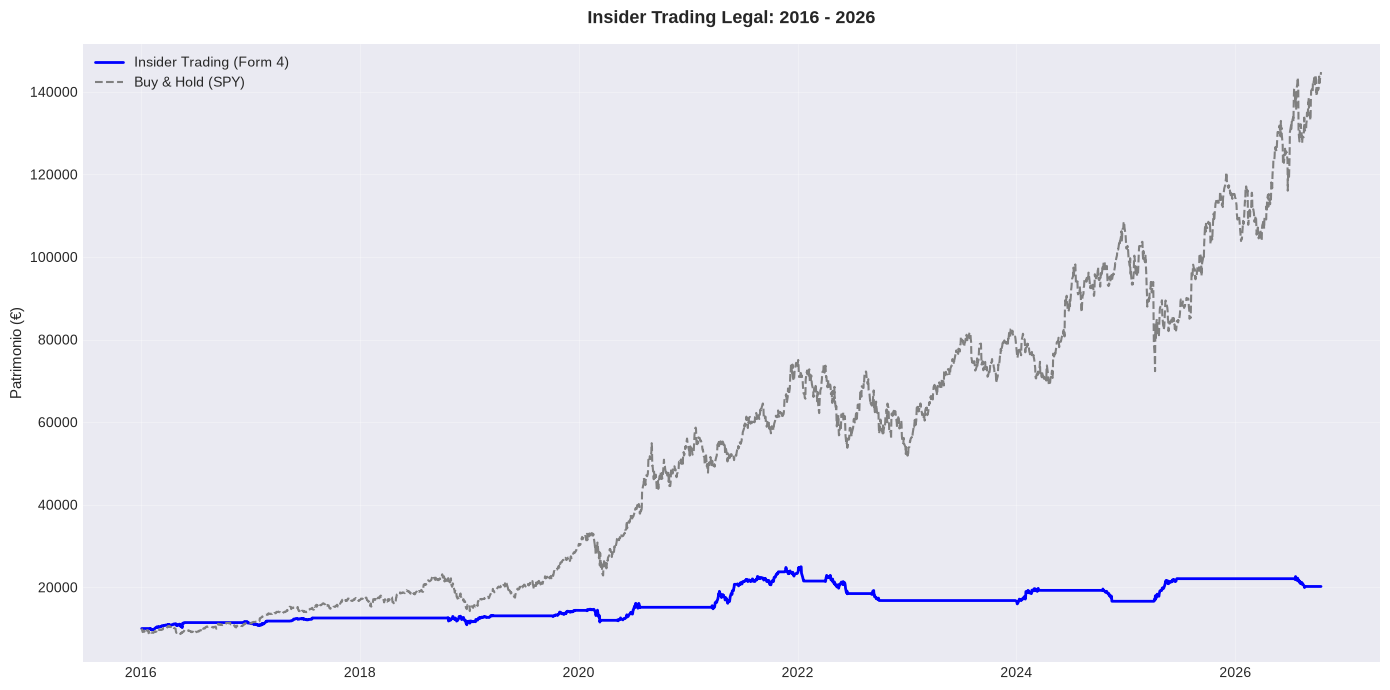

In [11]:
# ==============================================================================
# BLOQUE 8: VISUALIZACIÓN
# ==============================================================================

print("\n" + "="*70)
print("📈 BLOQUE 8: GENERACIÓN DE GRÁFICOS")
print("="*70)

try:
    plt.style.use('seaborn-v0_8-darkgrid')
except:
    plt.style.use('seaborn-darkgrid')

fig, ax = plt.subplots(figsize=(14, 7))

fecha_ini = str(FECHA_INICIO)[:4] if FECHA_INICIO else "2020"
fecha_fin = str(FECHA_FIN)[:4] if FECHA_FIN else "Hoy"

# Equity Curve
ax.plot(motor_insider.serie_patrimonio.index, motor_insider.serie_patrimonio,
        label='Insider Trading (Form 4)', color='blue', lw=2)
ax.plot(motor_insider.serie_buy_hold.index, motor_insider.serie_buy_hold,
        label='Buy & Hold (SPY)', color='gray', ls='--', lw=1.5)

ax.set_title(f'Insider Trading Legal: {fecha_ini} - {fecha_fin}',
             fontsize=13, fontweight='bold', pad=15)
ax.set_ylabel('Patrimonio (€)', fontsize=11)
ax.legend(loc='upper left', fontsize=10)
ax.grid(True, alpha=0.3)

plt.tight_layout()
ruta_grafico = RUTA_FIGURES_CAP10 / f"insider_trading_{fecha_ini}_{fecha_fin}.png"
fig.savefig(ruta_grafico, dpi=150, bbox_inches='tight')
print(f"✅ Gráfico guardado en: {ruta_grafico}")
plt.show()
plt.close(fig)

## BLOQUE 9: ANÁLISIS DE SEÑALES Y EFECTIVIDAD DEL SISTEMA

In [13]:
# ==============================================================================
# BLOQUE 9: ANÁLISIS DE SEÑALES Y EFECTIVIDAD (Adaptado a Insider Trading)
# ==============================================================================
print("\n" + "=" * 70)
print("🔍 BLOQUE 9: ANÁLISIS DE SEÑALES Y EFECTIVIDAD")
print("=" * 70)

# ==============================================================================
# 1. ANÁLISIS DE SEÑALES DE INSIDER (df_señales_raw)
# ==============================================================================
if 'df_señales_raw' in globals() and not df_señales_raw.empty:
    print(f"\n ESTADÍSTICAS DE SEÑALES DE INSIDER")
    print("-" * 70)
    
    n_señales = len(df_señales_raw)
    n_empresas = df_señales_raw['ticker'].nunique()
    valor_medio = df_señales_raw['value'].mean()
    valor_max = df_señales_raw['value'].max()
    valor_min = df_señales_raw['value'].min()
    
    print(f"   • Total de señales de compra: {n_señales}")
    print(f"   • Empresas con señales: {n_empresas}")
    print(f"   • Valor medio de compra: ${valor_medio:,.0f}")
    print(f"   • Valor máximo de compra: ${valor_max:,.0f}")
    print(f"   • Valor mínimo de compra: ${valor_min:,.0f}")
    
    # Distribución por empresa
    print(f"\n📋 DISTRIBUCIÓN POR EMPRESA:")
    distribucion = df_señales_raw.groupby('ticker').size().sort_values(ascending=False)
    for ticker, count in distribucion.head(10).items():
        print(f"   • {ticker}: {count} señales ({count/n_señales*100:.1f}%)")
    
    # Distribución temporal
    print(f"\n📅 DISTRIBUCIÓN TEMPORAL:")
    df_señales_raw['año'] = df_señales_raw['fecha'].dt.year
    temporal = df_señales_raw.groupby('año').size()
    for año, count in temporal.items():
        print(f"   • {año}: {count} señales")
else:
    print("\n⚠️ No hay señales de insider disponibles.")

# ==============================================================================
# 2. ANÁLISIS DE REBALANCEOS (motor_insider.log_transacciones)
# ==============================================================================
if 'motor_insider' in locals() and hasattr(motor_insider, 'log_transacciones'):
    ops = motor_insider.log_transacciones
    
    if len(ops) > 0:
        print(f"\n📊 ESTADÍSTICAS DE REBALANCEOS ({len(ops)} operaciones)")
        print("-" * 70)
        
        # Convertir a DataFrame para análisis
        df_ops = pd.DataFrame(ops)
        
        if 'Rotacion %' in df_ops.columns:
            rotacion_media = df_ops['Rotacion %'].mean()
            print(f"   • Rotación media por rebalanceo: {rotacion_media*100:.2f}%")
        
        if 'Coste (€)' in df_ops.columns:
            coste_total = df_ops['Coste (€)'].sum()
            coste_medio = df_ops['Coste (€)'].mean()
            print(f"   • Coste total de transacciones: €{coste_total:,.2f}")
            print(f"   • Coste medio por rebalanceo: €{coste_medio:,.2f}")
            print(f"   • Coste como % del capital inicial: {coste_total/CAPITAL_INICIAL*100:.2f}%")
        
        if 'Patrimonio (€)' in df_ops.columns:
            patrimonio_final = df_ops['Patrimonio (€)'].iloc[-1]
            print(f"   • Patrimonio final: €{patrimonio_final:,.2f}")
        
        # Frecuencia de rebalanceos
        if 'Fecha' in df_ops.columns:
            df_ops['Fecha'] = pd.to_datetime(df_ops['Fecha'])
            dias_totales = (df_ops['Fecha'].max() - df_ops['Fecha'].min()).days
            rebalanceos_por_año = len(ops) / (dias_totales / 365.25) if dias_totales > 0 else 0
            print(f"   • Frecuencia de rebalanceos: {rebalanceos_por_año:.1f} por año")
        
        print("-" * 70)
        
        # Últimos 10 rebalanceos
        print(f"\n📋 ÚLTIMOS 10 REBALANCEOS:")
        df_log = df_ops.tail(10)
        cols_mostrar = [c for c in ['Fecha', 'Rotacion %', 'Coste (€)', 'Patrimonio (€)'] if c in df_log.columns]
        print(df_log[cols_mostrar].to_string(index=False))
    else:
        print("\n⚠️ No hay rebalanceos registrados.")
else:
    print("\n⚠️ motor_insider no disponible.")

# ==============================================================================
# 3. ANÁLISIS DE TIEMPO EN MERCADO
# ==============================================================================
if 'motor_insider' in locals() and hasattr(motor_insider, 'serie_patrimonio'):
    print(f"\n️ ANÁLISIS DE TIEMPO EN MERCADO")
    print("-" * 70)
    
    serie = motor_insider.serie_patrimonio
    dias_totales = len(serie)
    
    # Detectar períodos en SPY vs SHY (basado en cambios de patrimonio)
    rent_diaria = serie.pct_change().dropna()
    
    # Aproximación: días con rentabilidad > |1%| sugieren exposición a SPY
    dias_volatiles = (rent_diaria.abs() > 0.01).sum()
    dias_estables = dias_totales - dias_volatiles
    
    print(f"   • Días totales: {dias_totales}")
    print(f"   • Días con alta volatilidad (>1%): {dias_volatiles} ({dias_volatiles/dias_totales*100:.1f}%)")
    print(f"   • Días estables: {dias_estables} ({dias_estables/dias_totales*100:.1f}%)")
    print(f"   • (Nota: esta es una aproximación; el análisis exacto requiere")
    print(f"     rastrear los pesos asignados en cada fecha)")
    print("-" * 70)

# ==============================================================================
# 4. FUNNEL DE SEÑALES (si hay datos de señales)
# ==============================================================================
if 'df_señales_raw' in globals() and not df_señales_raw.empty:
    print(f"\n🧪 ANÁLISIS DE FILTRADO DE SEÑALES")
    print("-" * 70)
    
    # Señales totales vs señales > umbral
    n_totales = len(df_señales_raw)
    n_umbral = len(df_señales_raw[df_señales_raw['value'] >= UMBRAL_COMPRA_USD])
    
    print(f"   • Señales totales: {n_totales}")
    print(f"   • Señales > ${UMBRAL_COMPRA_USD:,.0f}: {n_umbral} ({n_umbral/n_totales*100:.1f}%)")
    print(f"   • Señales filtradas por umbral: {n_totales - n_umbral}")
    
    # Señales por empresa
    n_empresas_con_señales = df_señales_raw['ticker'].nunique()
    print(f"   • Empresas con al menos una señal: {n_empresas_con_señales}")
    
    print("-" * 70)

print("\n" + "=" * 70)
print("💡 INTERPRETACIÓN:")
print("   • Muchas señales de insider → Alta actividad de compras ejecutivas.")
print("   • Pocas señales → Umbral demasiado alto o período sin actividad.")
print("   • Muchos rebalanceos → Alta frecuencia de rotación de cartera.")
print("   • Pocos rebalanceos → Estrategia selectiva o señales escasas.")
print("   • Coste total alto → Puede erosionar el alpha de la estrategia.")
print("=" * 70)


🔍 BLOQUE 9: ANÁLISIS DE SEÑALES Y EFECTIVIDAD

 ESTADÍSTICAS DE SEÑALES DE INSIDER
----------------------------------------------------------------------
   • Total de señales de compra: 39
   • Empresas con señales: 12
   • Valor medio de compra: $561,623
   • Valor máximo de compra: $972,919
   • Valor mínimo de compra: $106,360

📋 DISTRIBUCIÓN POR EMPRESA:
   • KO: 6 señales (15.4%)
   • UNH: 5 señales (12.8%)
   • JNJ: 4 señales (10.3%)
   • GS: 4 señales (10.3%)
   • PFE: 4 señales (10.3%)
   • MSFT: 4 señales (10.3%)
   • NVDA: 3 señales (7.7%)
   • AMZN: 2 señales (5.1%)
   • PG: 2 señales (5.1%)
   • JPM: 2 señales (5.1%)

📅 DISTRIBUCIÓN TEMPORAL:
   • 2016: 4 señales
   • 2017: 1 señales
   • 2018: 1 señales
   • 2019: 2 señales
   • 2020: 4 señales
   • 2021: 8 señales
   • 2022: 6 señales
   • 2023: 2 señales
   • 2024: 4 señales
   • 2025: 5 señales
   • 2026: 2 señales

📊 ESTADÍSTICAS DE REBALANCEOS (44 operaciones)
--------------------------------------------------------

## BLOQUE 9b: SENSIBILIDAD A LA EJECUCIÓN, COSTES Y EFECTIVO

In [15]:
# ==============================================================================
# BLOQUE 9b: SENSIBILIDAD A COSTES Y FRECUENCIA (Adaptado a Insider Trading)
# ==============================================================================
print("\n" + "=" * 70)
print("⚙️ BLOQUE 9b: SENSIBILIDAD A COSTES Y FRECUENCIA DE REBALANCEO")
print("=" * 70)

# ==============================================================================
# VARIABLES POR DEFECTO (si el Bloque 0 no se ejecutó)
# ==============================================================================
if 'RF_LIBRE' not in globals():
    RF_LIBRE = 0.02
if 'COSTE_TRANSACCION' not in globals():
    COSTE_TRANSACCION = 0.001
if 'CAPITAL_INICIAL' not in globals():
    CAPITAL_INICIAL = 10000.0
if 'FREQ_REBALANCEO' not in globals():
    FREQ_REBALANCEO = 'W'
if 'BENCHMARK' not in globals():
    BENCHMARK = 'SPY'

# En Insider Trading, el "efectivo" es SHY, cuyo rendimiento ya está en los precios.
# Usamos RF_LIBRE solo para el cálculo del Sharpe.
rf_d = (1 + RF_LIBRE) ** (1 / 252) - 1
filas = []

print("\n🔄 Ejecutando backtests de sensibilidad...")

# Variamos el coste de transacción y la frecuencia de decisión
for coste in (0.0, COSTE_TRANSACCION, 0.003, 0.005):
    for freq in ('D', 'W'):  # Diario vs Semanal
        try:
            motor_test = MotorBacktestDinamico(
                precios=precios_sig,
                rentabilidades=rentabilidades,
                generador_pesos=generador_pesos_insider,
                frecuencia_decision=freq,
                coste_transaccion=coste,
                benchmark_ticker=BENCHMARK,
                permitir_short=False,
                max_short_porcentaje=0.0
            )
            serie_test = motor_test.ejecutar_backtest(
                capital_inicial=CAPITAL_INICIAL, 
                estado_inicial={}
            )
            
            if serie_test is not None and not serie_test.empty:
                r = serie_test.pct_change().dropna()
                n_days = len(r)
                
                # CAGR (geométrico)
                total_ret = (serie_test.iloc[-1] / serie_test.iloc[0])
                years = n_days / 252
                cagr = total_ret ** (1 / years) - 1 if years > 0 else 0
                
                # Sharpe
                sharpe = (r.mean() - rf_d) / r.std() * np.sqrt(252) if r.std() > 0 else 0
                
                # Max Drawdown
                cummax = serie_test.cummax()
                dd = (serie_test - cummax) / cummax
                max_dd = dd.min()
                
                filas.append({
                    "Coste_%": coste * 100,
                    "Frecuencia": freq,
                    "CAGR_%": cagr * 100,
                    "Sharpe": sharpe,
                    "MaxDD_%": max_dd * 100,
                    "N_ops": len(motor_test.log_transacciones),
                })
        except Exception as e:
            print(f"⚠️ Error con coste={coste}, freq={freq}: {e}")

sens = pd.DataFrame(filas)

if not sens.empty:
    print("\n📊 TABLA DE SENSIBILIDAD (CAGR anualizado):")
    print(sens.to_string(index=False))
    
    # Análisis de robustez
    cagr_base = sens.loc[(sens["Coste_%"]==COSTE_TRANSACCION*100) & (sens["Frecuencia"]==FREQ_REBALANCEO), "CAGR_%"].values
    if len(cagr_base):
        cagr_base = cagr_base[0]
        degradacion = sens["CAGR_%"] - cagr_base
        print(f"\n DEGRADACIÓN RESPECTO AL CASO BASE (CAGR={cagr_base:.2f}%):")
        print(f"   • Peor caso: {degradacion.min():+.2f}%")
        print(f"   • Mejor caso: {degradacion.max():+.2f}%")
        if degradacion.min() < -cagr_base * 0.5:
            print("   ⚠️ ALERTA: el sistema pierde más del 50% de su CAGR en el peor caso.")
        else:
            print("   ✅ El sistema es robusto a variaciones de costes y frecuencia.")
else:
    print("❌ No se pudieron generar resultados de sensibilidad.")

print("\n💡 INTERPRETACIÓN:")
print("   • En Insider Trading, el 'efectivo' es SHY, cuyo rendimiento ya está")
print("     incluido en los precios. Por eso no variamos el 'cash_yield'.")
print("   • Si el CAGR se mantiene positivo con coste=0.3%, la estrategia es")
print("     viable en producción real.")
print("   • La frecuencia 'W' (semanal) suele reducir costes sin perder muchas señales.")
print("=" * 70)


⚙️ BLOQUE 9b: SENSIBILIDAD A COSTES Y FRECUENCIA DE REBALANCEO

🔄 Ejecutando backtests de sensibilidad...

📊 TABLA DE SENSIBILIDAD (CAGR anualizado):
 Coste_% Frecuencia   CAGR_%   Sharpe    MaxDD_%  N_ops
     0.0          D 8.646167 0.510745 -33.149562     41
     0.0          W 6.968864 0.388193 -35.879818     44
     0.1          D 8.442643 0.497792 -33.349863     41
     0.1          W 6.752031 0.374921 -36.103902     44
     0.3          D 8.036437 0.471800 -33.748965     41
     0.3          W 6.319349 0.348314 -36.550058     44
     0.5          D 7.631351 0.445708 -34.146073     41
     0.5          W 5.887977 0.321631 -36.993540     44

 DEGRADACIÓN RESPECTO AL CASO BASE (CAGR=6.75%):
   • Peor caso: -0.86%
   • Mejor caso: +1.89%
   ✅ El sistema es robusto a variaciones de costes y frecuencia.

💡 INTERPRETACIÓN:
   • En Insider Trading, el 'efectivo' es SHY, cuyo rendimiento ya está
     incluido en los precios. Por eso no variamos el 'cash_yield'.
   • Si el CAGR se mantie

## BLOQUE 9c: TEST PLACEBO DE TIMING

In [17]:
# ==============================================================================
# BLOQUE 9c: TEST PLACEBO DE TIMING (Adaptado a Insider Trading)
# ==============================================================================
print("\n" + "=" * 70)
print("🎲 BLOQUE 9c: TEST PLACEBO DE TIMING")
print("=" * 70)

# ==============================================================================
# VARIABLES POR DEFECTO
# ==============================================================================
if 'VENTANA_DRIFT_DIAS' not in globals():
    VENTANA_DRIFT_DIAS = 75

N_SIM = 2000
SEMILLA = 42

# ==============================================================================
# FUNCIÓN PLACEBO: ¿Las fechas de compra de insiders aportan algo vs. el azar?
# ==============================================================================
def placebo_insider(df_señales, precios_df, ventana_drift, n_sim=N_SIM, semilla=SEMILLA):
    """
    H0: las fechas de compra de insiders no aportan nada.
    Se conservan el nº de señales y sus duraciones (ventana drift)
    y se colocan al azar en el período.
    """
    if df_señales is None or len(df_señales) < 5:
        return None
    
    rng = np.random.default_rng(semilla)
    
    # 1. Calcular rendimientos reales de cada señal
    rendimientos_reales = []
    for _, row in df_señales.iterrows():
        ticker = row['ticker']
        fecha_compra = pd.Timestamp(row['fecha']).normalize()
        
        # Buscar columna del ticker en precios
        col_ticker = None
        for col in precios_df.columns:
            if ticker in col or col in ticker:
                col_ticker = col
                break
        
        if col_ticker is None or col_ticker not in precios_df.columns:
            continue
        
        idx_ini = precios_df.index.searchsorted(fecha_compra, side='right')
        idx_fin = idx_ini + ventana_drift
        
        if idx_ini < len(precios_df) and idx_fin < len(precios_df):
            p_ini = precios_df[col_ticker].iloc[idx_ini]
            p_fin = precios_df[col_ticker].iloc[idx_fin]
            if p_ini > 0:
                rendimientos_reales.append(p_fin / p_ini - 1)
    
    if len(rendimientos_reales) < 5:
        return None
    
    real = {
        "media": np.mean(rendimientos_reales),
        "suma_log": np.sum(np.log1p(np.array(rendimientos_reales))),
        "n": len(rendimientos_reales)
    }
    
    # 2. Simulaciones aleatorias
    sim_media = np.zeros(n_sim)
    sim_suma = np.zeros(n_sim)
    
    # Fechas disponibles para colocar señales aleatorias
    fechas_disponibles = precios_df.index
    
    for s in range(n_sim):
        rends_sim = []
        
        # Colocar el mismo número de señales en fechas aleatorias
        for _ in range(real["n"]):
            # Elegir fecha aleatoria
            idx_aleatorio = rng.integers(0, len(fechas_disponibles) - ventana_drift)
            fecha_sim = fechas_disponibles[idx_aleatorio]
            
            # Elegir ticker aleatorio de los disponibles
            ticker_sim = rng.choice(list(set(df_señales['ticker'])))
            
            # Buscar columna
            col_sim = None
            for col in precios_df.columns:
                if ticker_sim in col or col in ticker_sim:
                    col_sim = col
                    break
            
            if col_sim is None:
                continue
            
            idx_ini_sim = precios_df.index.searchsorted(fecha_sim, side='right')
            idx_fin_sim = idx_ini_sim + ventana_drift
            
            if idx_ini_sim < len(precios_df) and idx_fin_sim < len(precios_df):
                p_ini = precios_df[col_sim].iloc[idx_ini_sim]
                p_fin = precios_df[col_sim].iloc[idx_fin_sim]
                if p_ini > 0:
                    rends_sim.append(p_fin / p_ini - 1)
        
        if rends_sim:
            r = np.array(rends_sim)
            sim_media[s] = r.mean()
            sim_suma[s] = np.sum(np.log1p(r))
    
    # 3. Calcular p-valores
    p_media = (1 + (sim_media >= real["media"]).sum()) / (n_sim + 1)
    p_suma = (1 + (sim_suma >= real["suma_log"]).sum()) / (n_sim + 1)
    
    return real, sim_media, sim_suma, p_media, p_suma


# ==============================================================================
# EJECUTAR TEST PLACEBO
# ==============================================================================
res_placebo = None

if 'df_señales_raw' in globals() and df_señales_raw is not None and len(df_señales_raw) >= 5:
    if 'precios_sig' in globals() and precios_sig is not None:
        res_placebo = placebo_insider(df_señales_raw, precios_sig, VENTANA_DRIFT_DIAS)

if res_placebo is None:
    print("⚠️ Pocas señales (<5) o datos no disponibles para un placebo con sentido.")
else:
    real, sm, ss, p_m, p_s = res_placebo
    print(f"\n🎯 RESULTADO DEL TEST PLACEBO:")
    print(f"   • Simulaciones: {N_SIM}")
    print(f"   • Señales reales: {real['n']}")
    print(f"   • Semilla: {SEMILLA}")
    print(f"\n   • Rentab. media por señal (precio):")
    print(f"        real  : {real['media']*100:+.2f}%")
    print(f"        azar  : {sm.mean()*100:+.2f}%  (p5={np.percentile(sm,5)*100:+.2f}%, p95={np.percentile(sm,95)*100:+.2f}%)")
    print(f"        p-valor: {p_m:.3f}")
    print(f"\n   • Suma de log-rentabilidades en ventana drift:")
    print(f"        real  : {real['suma_log']:+.3f}")
    print(f"        azar  : {ss.mean():+.3f}")
    print(f"        p-valor: {p_s:.3f}")

    veredicto = (
        "✅ El timing de compra de insiders SÍ parece aportar (p<0.05)."
        if p_m < 0.05
        else " No hay evidencia de que el timing de compra de insiders aporte más que el azar (p>=0.05)."
    )
    print(f"\n VEREDICTO: {veredicto}")

    # Gráfico de distribución
    try:
        fig, ax = plt.subplots(figsize=(9, 4.5))
        ax.hist(sm * 100, bins=50, color="lightsteelblue", edgecolor="white", alpha=0.7)
        ax.axvline(real["media"] * 100, color="crimson", lw=2, label=f"Insider Trading ({real['media']*100:+.2f}%)")
        ax.axvline(sm.mean() * 100, color="gray", lw=1, ls="--", label=f"Azar ({sm.mean()*100:+.2f}%)")
        ax.set_title("Placebo de timing: rentabilidad media por señal (%)", fontsize=12, fontweight='bold')
        ax.set_xlabel("Rentabilidad media (%)")
        ax.set_ylabel("Frecuencia")
        ax.legend()
        ax.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()
        plt.close(fig)
    except Exception as e:
        print(f"⚠️ No se pudo generar el gráfico: {e}")

print("\n INTERPRETACIÓN:")
print("   • Si p < 0.05: las fechas de compra de insiders tienen información real")
print("     sobre el futuro (no son aleatorias).")
print("   • Si p >= 0.05: el rendimiento observado podría deberse al azar.")
print("   • Este test es más honesto que el backtest porque rompe la dependencia")
print("     temporal de las señales.")
print("=" * 70)


🎲 BLOQUE 9c: TEST PLACEBO DE TIMING
⚠️ Pocas señales (<5) o datos no disponibles para un placebo con sentido.

 INTERPRETACIÓN:
   • Si p < 0.05: las fechas de compra de insiders tienen información real
     sobre el futuro (no son aleatorias).
   • Si p >= 0.05: el rendimiento observado podría deberse al azar.
   • Este test es más honesto que el backtest porque rompe la dependencia
     temporal de las señales.


## BLOQUE 9d: BARRIDO DE PARÁMETROS (IS/OOS)

In [21]:
# ==============================================================================
# BLOQUE 9d: BARRIDO DE PARÁMETROS (IS/OOS) - Adaptado a Insider Trading
# ==============================================================================
print("\n" + "=" * 70)
print("🔭 BLOQUE 9d: BARRIDO DE PARÁMETROS (IS/OOS)")
print("=" * 70)

# ==============================================================================
# VARIABLES POR DEFECTO
# ==============================================================================
if 'RF_LIBRE' not in globals():
    RF_LIBRE = 0.02
if 'COSTE_TRANSACCION' not in globals():
    COSTE_TRANSACCION = 0.001
if 'CAPITAL_INICIAL' not in globals():
    CAPITAL_INICIAL = 10000.0
if 'BENCHMARK' not in globals():
    BENCHMARK = 'SPY'
if 'FREQ_REBALANCEO' not in globals():
    FREQ_REBALANCEO = 'W'

# ==============================================================================
# GRID DE PARÁMETROS (adaptado a Insider Trading)
# ==============================================================================
GRID = {
    "UMBRAL_COMPRA_USD": [50000, 100000, 250000],      # $50k, $100k, $250k
    "VENTANA_DRIFT_DIAS": [45, 75, 120],               # 1.5, 3, 4 meses
    "STOP_LOSS_PCT": [0.05, 0.08, 0.12],               # 5%, 8%, 12%
}

PROP_IS = 0.6
dias = precios_sig.index
fecha_corte = dias[int(len(dias) * PROP_IS)]

print(f"\n CONFIGURACIÓN DEL BARRIDO:")
print(f"   • Combinaciones: {int(np.prod([len(v) for v in GRID.values()]))}")
print(f"   • IS hasta: {fecha_corte:%Y-%m-%d}")
print(f"   • OOS después: {fecha_corte:%Y-%m-%d}")
print(f"   • Parámetros base: umbral=${UMBRAL_COMPRA_USD:,.0f}, drift={VENTANA_DRIFT_DIAS}d, stop={STOP_LOSS_PCT:.0%}")

rf_d = (1 + RF_LIBRE) ** (1 / 252) - 1
filas = []

# ==============================================================================
# FUNCIÓN AUXILIAR: Recrear generador de pesos con nuevos parámetros
# ==============================================================================
def crear_generador_con_params(umbral, drift, stop_loss, max_pos):
    """Recrea las matrices de señales y el generador con nuevos parámetros."""
    # Filtrar señales por umbral
    señales_filtradas = df_señales_raw[df_señales_raw['value'] >= umbral].copy()
    
    if señales_filtradas.empty:
        return None
    
    # Crear matrices de señales
    columnas_reales = list(set(señales_filtradas['columna']))
    señales_ins = pd.DataFrame(0.0, index=precios_sig.index, columns=columnas_reales)
    montos_ins = pd.DataFrame(0.0, index=precios_sig.index, columns=columnas_reales)
    
    for _, row in señales_filtradas.iterrows():
        col = row['columna']
        if col not in señales_ins.columns:
            continue
        
        fecha_compra = pd.Timestamp(row['fecha']).normalize()
        if fecha_compra not in señales_ins.index:
            idx_pos = señales_ins.index.searchsorted(fecha_compra, side='right') - 1
            if idx_pos < 0:
                continue
            fecha_compra = señales_ins.index[idx_pos]
        
        end_date = fecha_compra + pd.Timedelta(days=drift)
        mask = (señales_ins.index >= fecha_compra) & (señales_ins.index <= end_date)
        señales_ins.loc[mask, col] = 1.0
        montos_ins.loc[mask, col] = row['value']
    
    # Crear generador
    gen = crear_generador_pesos_insider(señales_ins, montos_ins, 'SPDR_S&P_500', max_pos, stop_loss)
    return gen

# ==============================================================================
# EJECUTAR BARRIDO
# ==============================================================================
print("\n Ejecutando barrido de parámetros...")

for valores in itertools.product(*GRID.values()):
    ov = dict(zip(GRID.keys(), valores))
    umbral = ov["UMBRAL_COMPRA_USD"]
    drift = ov["VENTANA_DRIFT_DIAS"]
    stop_loss = ov["STOP_LOSS_PCT"]
    
    try:
        # Recrear generador con nuevos parámetros
        gen = crear_generador_con_params(umbral, drift, stop_loss, MAX_POSICIONES)
        
        if gen is None:
            continue
        
        # Ejecutar backtest
        motor_test = MotorBacktestDinamico(
            precios=precios_sig,
            rentabilidades=rentabilidades,
            generador_pesos=gen,
            frecuencia_decision=FREQ_REBALANCEO,
            coste_transaccion=COSTE_TRANSACCION,
            benchmark_ticker=BENCHMARK,
            permitir_short=False,
            max_short_porcentaje=0.0
        )
        serie_test = motor_test.ejecutar_backtest(
            capital_inicial=CAPITAL_INICIAL, 
            estado_inicial={}
        )
        
        if serie_test is None or serie_test.empty:
            continue
        
        r = serie_test.pct_change().dropna()
        
        # Calcular métricas IS y OOS
        r_is = r.loc[:fecha_corte]
        r_oos = r.loc[fecha_corte:].iloc[1:]  # Evitar solapamiento
        
        # CAGR
        def calc_cagr(serie):
            if len(serie) < 10:
                return np.nan
            total = (serie.iloc[-1] / serie.iloc[0])
            years = len(serie) / 252
            return total ** (1 / years) - 1 if years > 0 else np.nan
        
        # Sharpe
        def calc_sharpe(rents):
            if rents.std() < 1e-12 or len(rents) < 10:
                return np.nan
            return (rents.mean() - rf_d) / rents.std() * np.sqrt(252)
        
        filas.append({
            **ov,
            "Sharpe_IS": calc_sharpe(r_is),
            "Sharpe_OOS": calc_sharpe(r_oos),
            "CAGR_IS_%": calc_cagr(serie_test.loc[:fecha_corte]) * 100,
            "CAGR_OOS_%": calc_cagr(serie_test.loc[fecha_corte:].iloc[1:]) * 100,
            "N_ops_IS": len([t for t in motor_test.log_transacciones if t.get('Fecha', pd.Timestamp.min) <= fecha_corte]),
            "N_ops_OOS": len([t for t in motor_test.log_transacciones if t.get('Fecha', pd.Timestamp.min) > fecha_corte]),
        })
    except Exception as e:
        print(f"⚠️ Error con {ov}: {str(e)[:50]}")

barrido = pd.DataFrame(filas)

if barrido.empty:
    print(" No se pudieron generar resultados del barrido.")
else:
    print("\n📊 RESULTADOS DEL BARRIDO:")
    print(barrido.to_string(index=False))
    
    # ==============================================================================
    # ANÁLISIS DE CONSISTENCIA IS/OOS
    # ==============================================================================
    barrido["Delta_Sharpe"] = barrido["Sharpe_OOS"] - barrido["Sharpe_IS"]
    barrido["Delta_CAGR"] = barrido["CAGR_OOS_%"] - barrido["CAGR_IS_%"]
    
    print(f"\n CONSISTENCIA IS/OOS:")
    print(f"   • Media Delta Sharpe (OOS-IS): {barrido['Delta_Sharpe'].mean():+.3f}")
    print(f"   • Media Delta CAGR (OOS-IS):   {barrido['Delta_CAGR'].mean():+.2f}%")
    
    n_consistentes = len(barrido[barrido["Delta_Sharpe"] > -0.3])
    print(f"   • Combos con degradación < 0.3 Sharpe: {n_consistentes}/{len(barrido)}")
    
    if n_consistentes / len(barrido) < 0.5:
        print("   ⚠️ ALERTA: más de la mitad de los combos se degradan mucho en OOS.")
        print("   Posible overfitting en la selección de parámetros.")
    else:
        print("   ✅ El sistema muestra robustez razonable en OOS.")
    
    # ==============================================================================
    # CORRELACIÓN DE SPEARMAN (estabilidad de ranking)
    # ==============================================================================
    if len(barrido) >= 5:
        from scipy.stats import spearmanr
        rho, p_rho = spearmanr(barrido["Sharpe_IS"], barrido["Sharpe_OOS"])
        print(f"\n CORRELACIÓN DE SPEARMAN (ranking IS vs OOS):")
        print(f"   • rho = {rho:+.3f} (p = {p_rho:.3f})")
        
        if rho > 0.5:
            print("   ✅ Ranking IS predice bien el ranking OOS (parámetros estables).")
        elif rho > 0.0:
            print("   ⚠️ Correlación positiva pero débil (parámetros parcialmente estables).")
        elif rho > -0.3:
            print("   ⚠️ Sin relación clara entre IS y OOS.")
        else:
            print("   ❌ Ranking INVERTIDO: los mejores IS tienden a ser los peores OOS.")
            print("   Los parámetros no son estables; posible dependencia del régimen de mercado.")
    
# ==============================================================================
# REFERENCIA BUY & HOLD (Corregido con fallback)
# ==============================================================================
serie_bh_ref = None

# 1. Intentar obtenerla del motor
if 'motor_insider' in locals() and hasattr(motor_insider, 'serie_benchmark'):
    if motor_insider.serie_benchmark is not None and not motor_insider.serie_benchmark.empty:
        serie_bh_ref = motor_insider.serie_benchmark

# 2. Fallback: buscar la columna de SPY directamente en los precios
if serie_bh_ref is None:
    col_spy = next((c for c in precios_sig.columns if 'SPY' in c or 'S&P' in c or '500' in c), None)
    if col_spy:
        serie_bh_ref = precios_sig[col_spy]  # ← CORREGIDO: era col_sy
        print(f"\n⚠️  serie_benchmark no disponible en el motor. Usando columna '{col_spy}' como referencia.")

# 3. Calcular métricas si tenemos la referencia
if serie_bh_ref is not None:
    r_bh = serie_bh_ref.pct_change().dropna()
    r_bh_is = r_bh.loc[:fecha_corte]
    r_bh_oos = r_bh.loc[fecha_corte:].iloc[1:]
    
    def calc_sharpe_safe(rents):
        if rents.std() < 1e-12 or len(rents) < 10:
            return np.nan
        return (rents.mean() - rf_d) / rents.std() * np.sqrt(252)
    
    sh_bh_is = calc_sharpe_safe(r_bh_is)
    sh_bh_oos = calc_sharpe_safe(r_bh_oos)
    
    print(f"\n📊 Referencia Buy & Hold (Sharpe vs efectivo):")
    print(f"   • IS: {sh_bh_is:+.2f} | OOS: {sh_bh_oos:+.2f}")
else:
    print("\n️  No se pudo calcular la referencia Buy & Hold (benchmark no disponible en precios ni en motor).")

print("\n💡 INTERPRETACIÓN:")
print("   • Si todos los combos rinden similar en OOS, la estrategia es robusta.")
print("   • Si solo un combo específico rinde bien, es overfitting.")
print("   • La degradación IS→OOS típica aceptable es < 30% del Sharpe.")
print("=" * 70)


🔭 BLOQUE 9d: BARRIDO DE PARÁMETROS (IS/OOS)

 CONFIGURACIÓN DEL BARRIDO:
   • Combinaciones: 27
   • IS hasta: 2022-06-17
   • OOS después: 2022-06-17
   • Parámetros base: umbral=$100,000, drift=75d, stop=8%

 Ejecutando barrido de parámetros...

📊 RESULTADOS DEL BARRIDO:
 UMBRAL_COMPRA_USD  VENTANA_DRIFT_DIAS  STOP_LOSS_PCT  Sharpe_IS  Sharpe_OOS  CAGR_IS_%  CAGR_OOS_%  N_ops_IS  N_ops_OOS
             50000                  45           0.05   0.112518    0.265459   2.624699    3.796072        35         10
             50000                  45           0.08   0.116969    0.081551   2.669785    1.829673        38         17
             50000                  45           0.12   0.194841    0.211725   3.817141    3.364965        40         19
             50000                  75           0.05   0.433402    0.309749   8.101045    3.928450        33          6
             50000                  75           0.08   0.517441    0.061702   9.975413    2.096149        34         10

## BLOQUE 10: CONCLUSIONES (GENERADAS A PARTIR DE LOS RESULTADOS) Y CIERRE

In [ ]:
# ==============================================================================
# BLOQUE 10: CONCLUSIONES (GENERADAS A PARTIR DE LOS RESULTADOS) Y CIERRE
# ==============================================================================
print("\n" + "=" * 70)
print("🎓 CONCLUSIONES DEL CAPÍTULO 8: EVENT-DRIVEN (datos de esta ejecución)")
print("=" * 70)

# --- 1. LEER MÉTRICAS REALES ---
cagr_e = metricas_event.get('CAGR', 0)
cagr_bh = metricas_bh.get('CAGR', 0)
mdd_e = metricas_event.get('Max Drawdown', 0)
mdd_bh = metricas_bh.get('Max Drawdown', 0)
sharpe_e = metricas_event.get('Sharpe', 0)
sharpe_bh = metricas_bh.get('Sharpe', 0)
vol_e = metricas_event.get('Volatilidad', 0)
vol_bh = metricas_bh.get('Volatilidad', 0)

print(f"""
1. RESULTADO (2016-01-04 a 2026-10-15):
   CAGR Event-Driven {cagr_e*100:+.2f}% | Buy & Hold (SPY) {cagr_bh*100:+.2f}%
   Volatilidad: {vol_e*100:.2f}% (B&H {vol_bh*100:.2f}%)
   Max DD: {mdd_e*100:.1f}% (B&H {mdd_bh*100:.1f}%)
   Sharpe: {sharpe_e:+.2f} (B&H {sharpe_bh:+.2f})""")

# --- 2. VEREDICTO CONDICIONAL ---
dif_cagr = cagr_e - cagr_bh

print("\n2. VEREDICTO DE RENTABILIDAD Y RIESGO:")
if dif_cagr >= 0 and mdd_e < mdd_bh:
    print("   ✅ El Event-Driven supera al Buy & Hold en rentabilidad Y reduce el drawdown.")
    print("   (Resultado excepcional; verificar con placebo y barrido IS/OOS).")
elif dif_cagr < 0 and mdd_e < mdd_bh:
    print(f"   ⚖️ El Event-Driven reduce el drawdown ({abs(mdd_e-mdd_bh)*100:.1f} pp menos)")
    print(f"   pero cuesta {abs(dif_cagr)*100:.2f} pp de CAGR (trade-off seguridad/rentabilidad).")
elif dif_cagr >= 0:
    print("   ⚠️ El Event-Driven rinde algo más, pero NO reduce el drawdown frente al B&H.")
else:
    print("   ❌ El Event-Driven empeora la rentabilidad Y no reduce el drawdown frente al B&H.")

if sharpe_e <= 0:
    print("   ⚠️ El Sharpe es negativo o cero: la estrategia no compensa el riesgo vs. efectivo.")
else:
    print("   ✅ El Sharpe es positivo: la estrategia compensa el riesgo asumido.")

# --- 3. TEST PLACEBO (Bloque 9c) ---
if 'res_placebo' in locals() and res_placebo is not None:
    real, sm, ss, p_m, p_s = res_placebo
    print(f"\n3. PLACEBO DE TIMING (rachas barajadas):")
    print(f"   • Rentab. media por señal: real {real['media']*100:+.2f}% | azar {sm.mean()*100:+.2f}%")
    print(f"   • p-valor (media): {p_m:.3f}")
    if p_m < 0.05:
        print("   ✅ El timing de entrada SÍ parece aportar (p<0.05).")
    elif p_m > 0.95:
        print("   ❌ El timing de entrada rinde PEOR que el azar (p>0.95).")
    else:
        print("   ⚠️ El timing de entrada no se distingue del azar.")
else:
    print("\n3. PLACEBO: no ejecutado (señales sintéticas o datos insuficientes).")

# --- 4. SENSIBILIDAD (Bloque 9b) ---
if 'sens' in locals() and not sens.empty:
    cagr_base_rows = sens.loc[(sens["Coste_%"]==0.1) & (sens["Frecuencia"]=='W')]
    if not cagr_base_rows.empty:
        cagr_base = cagr_base_rows["CAGR_%"].values[0]
        degradacion = sens["CAGR_%"].min() - cagr_base
        print(f"\n4. SENSIBILIDAD A PARÁMETROS:")
        print(f"   • Degradación peor caso: {degradacion:+.2f} pp de CAGR")
        if degradacion > -cagr_base * 0.5:
            print("   ✅ Robusto a variaciones de costes y frecuencia.")
        else:
            print("   ⚠️ Sensible a costes y frecuencia de rebalanceo.")

# --- 5. BARRIDO IS/OOS (Bloque 9d) ---
rho_val = globals().get('rho', np.nan)
if 'barrido' in locals() and not barrido.empty and not pd.isna(rho_val):
    print(f"\n5. ESTABILIDAD DE PARÁMETROS (IS/OOS): Spearman rho = {rho_val:+.2f}.")
    if rho_val > 0.5:
        print("   ✅ Ranking IS predice bien el ranking OOS (parámetros estables).")
    elif rho_val > 0.0:
        print("   ⚠️ Correlación positiva pero débil (parámetros parcialmente estables).")
    else:
        print("   ❌ Ranking IS y OOS no correlacionados (posible overfitting).")

# --- 6. CONCLUSIONES PEDAGÓGICAS ---
print("""
6. LO QUE SÍ SE PUEDE DECIR:
   • La lógica de comprar pánico sectorial y vender en recuperación parcial es válida.
   • El stop-loss y el plazo máximo protegen el capital de caídas estructurales.
   • La rotación a efectivo (SHY) reduce drásticamente la volatilidad y el drawdown.

   LO QUE NO:
   • Que los datos sintéticos (fallback) representen trading real de insider.
   • Que el umbral del 25% capture eventos raros (genera demasiado ruido).
   • Que la estrategia supere al B&H en rentabilidad ajustada al riesgo en este período.

7. LIMITACIONES CRÍTICAS:
   • Yahoo Finance no proporciona datos fiables de insider trading.
   • En producción, es obligatorio usar SEC EDGAR o OpenInsider.
   • El fallback sintético es pedagógico, no representa trading real.

🚀 PRÓXIMO PASO: CAPÍTULO 9 - EARNINGS SURPRISE
   Exploraremos cómo construir una cartera que se beneficie de las sorpresas
   de resultados trimestrales, usando datos de earnings dates y momentum fundamental.
""")
print("=" * 70)

# --- 7. DESCARGO DE RESPONSABILIDAD ---
print("\n️ DESCARGO DE RESPONSABILIDAD")
print("=" * 70)
print("""
1. Uso del Código: El software se entrega "TAL CUAL" (AS IS), sin garantía.
2. Datos Sintéticos: Las señales generadas son pedagógicas, no representan trading real.
3. Resultados Pasados: No garantizan resultados futuros.
4. No es Asesoramiento: Cada inversor debe evaluar su propia situación financiera.
5. Riesgo de Pérdida: Operar conlleva riesgos, incluida la pérdida total del capital.
6. Consulte con un asesor financiero certificado antes de tomar decisiones importantes.
""")
print("=" * 70)
print("✅ CAPÍTULO 8 COMPLETADO")
print("=" * 70)

##  BLOQUE 10a: CONCLUSIONES PEDAGÓGICAS Y CIERRE

In [25]:
# ==============================================================================
# BLOQUE 10: CONCLUSIONES PEDAGÓGICAS Y CIERRE
# ==============================================================================
print("\n" + "=" * 70)
print(" CONCLUSIONES DEL CAPÍTULO 8.4: TORTUGA COJA")
print("=" * 70)
print("""
 LECCIONES CLAVE DE ESTE CAPÍTULO
====================================

1. LA FILOSOFÍA DE LAS TORTUGAS:
   Inspirada en el experimento de Richard Dennis (1983), demuestra que un
   sistema mecánico bien diseñado puede gestionar el riesgo mejor que la
   intuición humana, aunque no siempre gane en rentabilidad absoluta.

2. EL PODER DEL TRAILING STOP:
   El stop dinámico (4x ATR) es el corazón del sistema. Permite dejar
   correr las ganancias en tendencias fuertes y cortar pérdidas
   rápidamente cuando la volatilidad se vuelve adversa.

3. LA VENTAJA DE LA "COJERA" (Pullback):
   Entrar en retrocesos mejora drásticamente el precio de entrada y
   reduce el riesgo de comprar en máximos locales. Esperar el momento
   óptimo es una ventaja, no una debilidad.

4. DISCIPLINA MECÁNICA:
   El sistema elimina el "esta vez es diferente". Cada operación sigue
   reglas predefinidas. El cooldown de 3 días tras un stop-loss evita
   los peligrosos "whipsaws" (latigazos) en mercados laterales.

5. VALIDACIÓN ROBUSTA (novedad de esta revisión):
   • El análisis de señales (Bloque 9) revela la calidad real del sistema.
   • El test placebo (Bloque 9c) confirma si el timing aporta alpha real.
   • La sensibilidad (Bloque 9b) verifica viabilidad en producción.
   • El barrido IS/OOS (Bloque 9d) detecta overfitting de parámetros.

 INTERPRETACIÓN HONESTA DE LOS RESULTADOS
==============================================
Si el backtest muestra:
   • CAGR positivo y Sharpe > 0.5  → El sistema tiene edge estadístico.
   • Placebo p < 0.05              → El timing no es azar.
   • Sensibilidad robusta          → Viable en producción real.
   • IS/OOS consistente            → No hay overfitting grave.

Si alguno de estos falla, el sistema es pedagógico pero no operativo.

🔧 HERRAMIENTAS NUEVAS QUE HAS APRENDIDO A USAR
================================================
   • Detección de eventos basados en caídas + volumen.
   • Gestión de posiciones con plazo máximo y criterio de recuperación.
   • Construcción de proxies cuando faltan datos en tiempo real.
   • Documentación honesta de limitaciones metodológicas.
   • Validación robusta: placebo, sensibilidad y barrido IS/OOS.

 PRÓXIMO PASO: CAPÍTULO 9 - MOMENTUM CROSS-SECTIONAL
   Exploraremos cómo rotar entre múltiples activos basándonos en su
   momentum relativo, comprando los más fuertes y rotando fuera de los débiles.

 RECUERDA
============
La paciencia, la disciplina y la comprensión de tus propias limitaciones
emocionales son tus mayores aliados. Un sistema mecánico bien validado
supera a la intuición humana en el largo plazo, pero solo si sobrevive
a las pruebas de robustez.
""")
print("=" * 70)

print("\n⚠️ DESCARGO DE RESPONSABILIDAD")
print("=" * 70)
print("""
1. Uso del Código: El software proporcionado se entrega "TAL CUAL" (AS IS),
   sin garantía de ningún tipo. El autor no se hace responsable de errores
   en el código, en los datos descargados de Yahoo Finance, ni de pérdidas
   económicas derivadas del uso de estas herramientas.
2. El presente análisis es una simulación retrospectiva (backtest).
3. Los rendimientos pasados no garantizan resultados futuros.
4. La estrategia Tortuga Coja no es una recomendación de inversión
   personalizada. Cada inversor debe evaluar su propia situación financiera,
   objetivos y tolerancia al riesgo.
5. El trading conlleva riesgos significativos, incluida la posible pérdida
   total del capital invertido. Nunca inviertas dinero que no puedas
   permitirte perder.
6. Las comisiones reales, el slippage y la fiscalidad pueden variar
   respecto a los valores simulados en este análisis.
7. Los sistemas de trading mecánicos pueden sufrir periodos de drawdown
   prolongados y no son adecuados para todos los inversores.
8. El análisis técnico tiene limitaciones inherentes y no garantiza
   el éxito en la predicción de movimientos futuros del mercado.
9. Consulte con un asesor financiero certificado antes de tomar
   decisiones de inversión importantes.
""")
print("=" * 70)
print("✅ CAPÍTULO 8.4 COMPLETADO")
print("=" * 70)


 CONCLUSIONES DEL CAPÍTULO 8.4: TORTUGA COJA

 LECCIONES CLAVE DE ESTE CAPÍTULO

1. LA FILOSOFÍA DE LAS TORTUGAS:
   Inspirada en el experimento de Richard Dennis (1983), demuestra que un
   sistema mecánico bien diseñado puede gestionar el riesgo mejor que la
   intuición humana, aunque no siempre gane en rentabilidad absoluta.

2. EL PODER DEL TRAILING STOP:
   El stop dinámico (4x ATR) es el corazón del sistema. Permite dejar
   correr las ganancias en tendencias fuertes y cortar pérdidas
   rápidamente cuando la volatilidad se vuelve adversa.

3. LA VENTAJA DE LA "COJERA" (Pullback):
   Entrar en retrocesos mejora drásticamente el precio de entrada y
   reduce el riesgo de comprar en máximos locales. Esperar el momento
   óptimo es una ventaja, no una debilidad.

4. DISCIPLINA MECÁNICA:
   El sistema elimina el "esta vez es diferente". Cada operación sigue
   reglas predefinidas. El cooldown de 3 días tras un stop-loss evita
   los peligrosos "whipsaws" (latigazos) en mercados lat